In [1]:
!pip install --upgrade mat-io scipy numpy pandas

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from matio import load_from_mat

In [7]:
import os
DATA_DIR = r"C:\Users\Maher\Desktop\CRISES ABSENCES"
tt = load_from_mat(os.path.join(DATA_DIR, "210208B_G_0000d.mat"))["output_d"]
print(tt.shape)

(1200, 21)


In [8]:
case = tt.iloc[0, 0]     # ligne 0, colonne 0
print(case.shape)


(256, 1)


In [ ]:
CANAUX = ['EEGFp1','EEGFp2','EEGF7','EEGF3','EEGFz','EEGF4','EEGF8','EEGT3','EEGC3',
          'EEGCz','EEGC4','EEGT4','EEGT5','EEGP3','EEGPz','EEGP4','EEGT6','EEGO1','EEGO2']
fs = 256

donnees = {}
for c in CANAUX:
    morceaux = [np.ravel(v) for v in tt[c]]      # chaque case -> liste de 256 valeurs
    donnees[c] = np.concatenate(morceaux)        # on colle toutes les secondes bout à bout

df = pd.DataFrame(donnees)
df.insert(0, "Time", np.arange(len(df)) / fs)    # colonne temps en secondes

In [10]:
print("Nombre de lignes     :", df.shape[0])
print("Nombre de variables  :", df.shape[1])
print("Fréquence (Hz)       :", fs)
print("Durée (s)            :", df.shape[0] / fs)
print("Valeurs manquantes   :", df.isna().sum().sum())
df.head()

Nombre de lignes     : 307200
Nombre de variables  : 20
Fréquence (Hz)       : 256
Durée (s)            : 1200.0
Valeurs manquantes   : 0


,Time,EEGFp1,EEGFp2,EEGF7,EEGF3,EEGFz,EEGF4,EEGF8,EEGT3,EEGC3,EEGCz,EEGC4,EEGT4,EEGT5,EEGP3,EEGPz,EEGP4,EEGT6,EEGO1,EEGO2
0,0.000000,-181.941634,-157.957198,-896.463035,-246.556420,-50.922179,-212.727626,-910.782101,-213.264591,-307.412451,-117.863813,-924.027237,-99.785992,-817.350195,-812.517510,-675.591440,-210.758755,-944.610895,-174.961089,-949.443580
1,0.003906,-154.914397,-131.108949,-872.120623,-220.782101,-23.357977,-190.354086,-885.365759,-181.404669,-278.953307,-90.478599,-899.147860,-76.696498,-786.027237,-782.447471,-647.848249,-186.237354,-914.898833,-146.501946,-936.914397
2,0.007812,-36.424125,-16.914397,-751.303502,-101.575875,87.972763,-76.338521,-768.128405,-57.902724,-159.389105,26.221790,-784.595331,39.645914,-659.303502,-657.155642,-527.031128,-70.610895,-796.408560,-17.809339,-819.498054
3,0.011719,14.050584,32.844358,-689.015564,-48.595331,131.645914,-26.937743,-714.073930,-5.459144,-110.167315,73.116732,-737.700389,92.626459,-603.459144,-605.964981,-480.852140,-24.610895,-744.680934,31.233463,-760.610895
4,0.015625,-71.147860,-51.280156,-768.128405,-132.361868,49.311284,-109.988327,-794.976654,-86.540856,-193.396887,-11.544747,-823.972763,9.217899,-684.361868,-685.256809,-564.797665,-112.136187,-832.027237,-46.447471,-839.007782


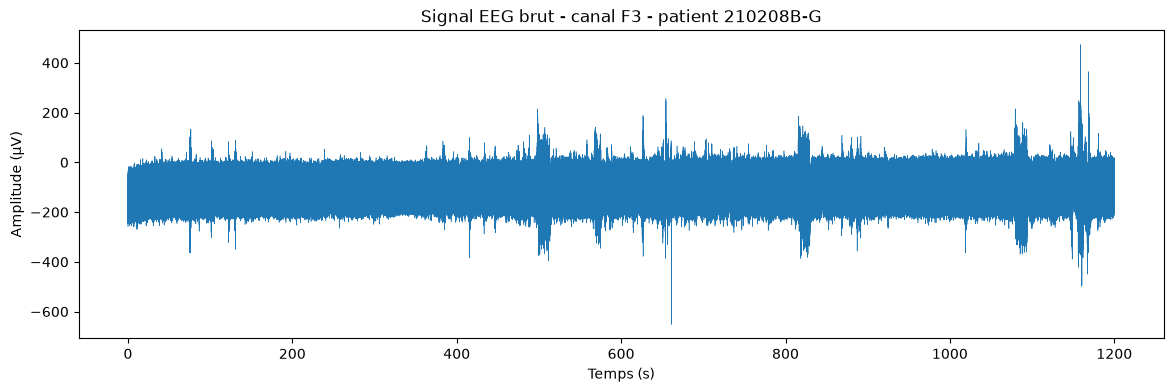

In [11]:
plt.figure(figsize=(14, 4))                    # taille du graphe (largeur, hauteur)
plt.plot(df["Time"], df["EEGF3"], lw=0.4)      # x = temps, y = canal F3 ; lw = épaisseur du trait
plt.title("Signal EEG brut - canal F3 - patient 210208B-G")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude (µV)")
plt.show()

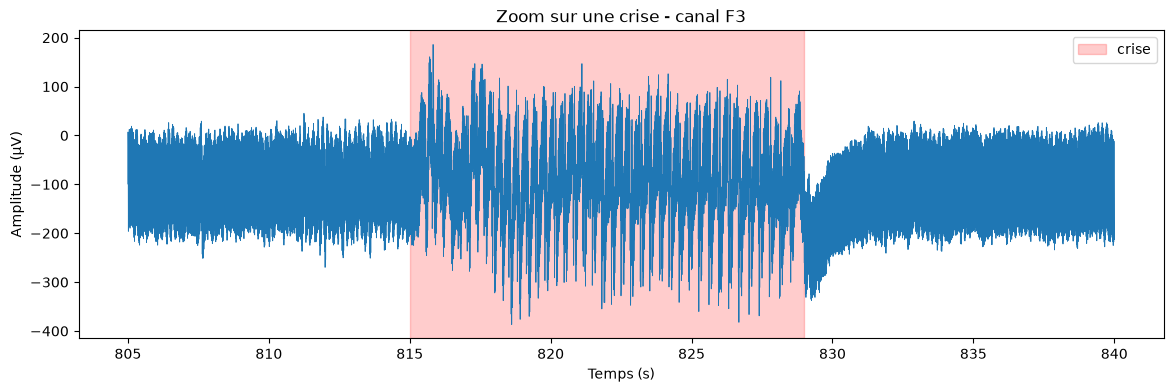

In [12]:
zone = (df["Time"] >= 805) & (df["Time"] <= 840)   # True seulement entre 805 et 840 s

plt.figure(figsize=(14, 4))
plt.plot(df["Time"][zone], df["EEGF3"][zone], lw=0.6)
plt.axvspan(815, 829, color="red", alpha=0.2, label="crise")   # colorie la crise en rouge
plt.title("Zoom sur une crise - canal F3")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude (µV)")
plt.legend()
plt.show()

In [13]:
from scipy.signal import butter, sosfiltfilt

sos = butter(4, [0.5, 40], btype="bandpass", fs=256, output="sos")

X_brut = df[CANAUX].values                  # tableau numpy (307200, 19)
X_filt = sosfiltfilt(sos, X_brut, axis=0)   # on filtre chaque colonne (axis=0 = le long du temps)

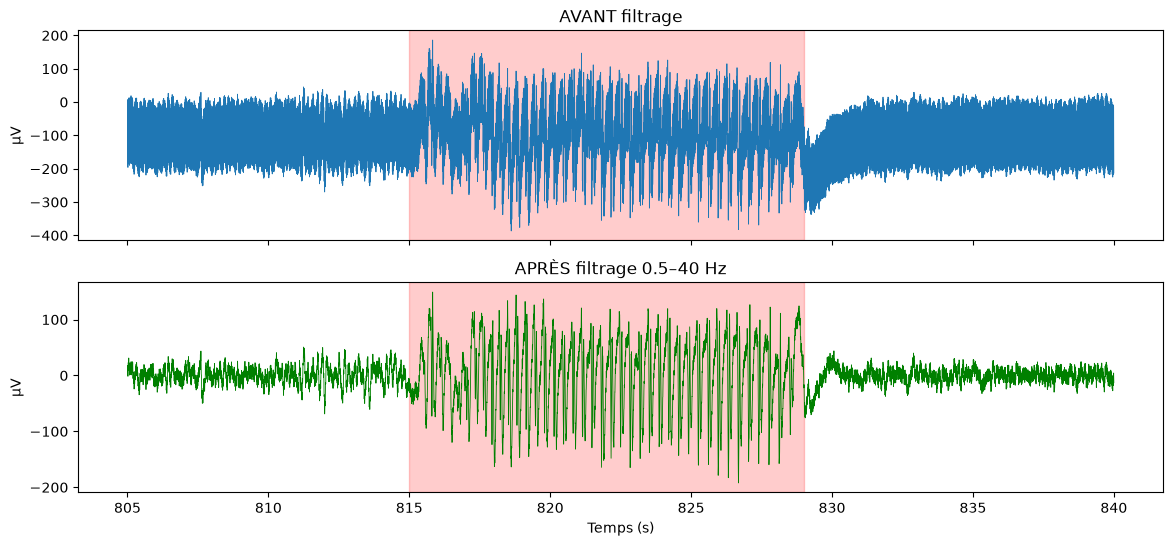

In [14]:
t = df["Time"].values
zone = (t >= 805) & (t <= 840)
c = CANAUX.index("EEGF3")          # numéro de la colonne F3

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(t[zone], X_brut[zone, c], lw=0.6)
axes[0].set_title("AVANT filtrage")
axes[1].plot(t[zone], X_filt[zone, c], lw=0.6, color="green")
axes[1].set_title("APRÈS filtrage 0.5–40 Hz")
for ax in axes:
    ax.axvspan(815, 829, color="red", alpha=0.2)
    ax.set_ylabel("µV")
axes[1].set_xlabel("Temps (s)")
plt.show()

In [17]:
xl = pd.read_excel(os.path.join(DATA_DIR, "Crises absences.xlsx"))
xl = xl.rename(columns={xl.columns[0]: "ID"})    # la 1re colonne n'a pas de nom -> on l'appelle "ID"
xl["ID"] = xl["ID"].astype(str).str.strip()      # enlève les espaces autour des noms
xl.head()


,ID,Sexe,Age,NombreCE,TypeAbs,DebCE1,FinCE1,DebCE2,FinCE2,DebCE3,FinCE3,DebCE4,FinCE4,DebutCE5,FinCE5,DebCE6,FinCE6,DebCE7,FinCE7,DebCE8,FinCE8,DebCE9,FinCE9,DebCE10,FinCE10,DebtCE11,FinCE11,DebCE12,FinCE12,Intercrit1,Intercrit2,Intercrit3,Intercrit4,Intercrit5,Intercrit6,Intercrit7
0,190304A-E,M,17.0,1.0,NaN,0.441042,0.441123,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.432396,NaN,NaN,NaN,NaN,NaN,NaN
1,191113A-D,F,25.0,2.0,NaN,0.443900,0.444051,0.445914,0.445972,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,200625A-F,M,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,210204B-C,F,5.0,6.0,NaN,0.431829,0.431887,0.433669,0.433727,0.436308,0.436366,0.437905,0.437940,0.4389,0.438947,0.444248,0.444306,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.433796,0.433808,0.433819,0.434815,0.434873,0.438391,0.439398
4,210208B-G,F,14.0,4.0,NaN,0.471678,0.471794,0.472500,0.472581,0.475359,0.475521,0.478403,0.478588,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.470359,0.470370,0.471412,0.471574,0.473403,0.473866,NaN


In [18]:
ligne = xl[xl["ID"] == "210208B-G"].iloc[0]      # la ligne du patient

crises_horloge = []
for k in range(1, 13):                           # au maximum 12 crises par patient
    deb = ligne.get(f"DebCE{k}")
    fin = ligne.get(f"FinCE{k}")
    if pd.notna(deb) and pd.notna(fin):          # on garde seulement les cases remplies
        crises_horloge.append((deb * 86400, fin * 86400))

for d, f in crises_horloge:
    print(pd.to_timedelta(d, unit="s"), "->", pd.to_timedelta(f, unit="s"), f"  durée {f-d:.0f} s")

0 days 11:19:13 -> 0 days 11:19:23   durée 10 s
0 days 11:20:24 -> 0 days 11:20:31   durée 7 s
0 days 11:24:31 -> 0 days 11:24:45   durée 14 s
0 days 11:28:54 -> 0 days 11:29:10   durée 16 s


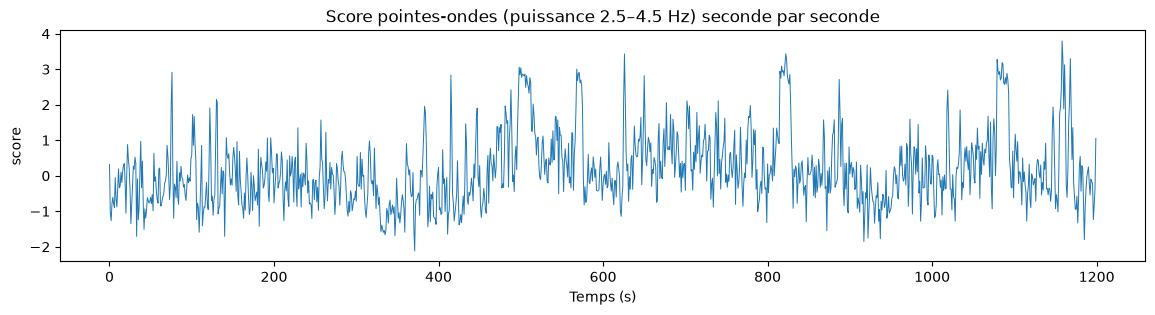

In [19]:
n = len(X_filt) // 256                         # nombre de secondes complètes (1200)
secondes = X_filt[: n*256].reshape(n, 256, 19) # on range le signal en blocs de 1 s

spectre = np.abs(np.fft.rfft(secondes, axis=1))**2   # FFT de chaque seconde -> puissance par fréquence
freqs = np.fft.rfftfreq(256, 1/256)                  # fréquences correspondantes : 0, 1, 2, ... 128 Hz

bande = (freqs >= 2.5) & (freqs <= 4.5)              # on garde 2.5 – 4.5 Hz (autour de 3 Hz)
score = np.log(spectre[:, bande, :].sum(axis=1) + 1e-6).mean(axis=1)  # somme dans la bande, log, moyenne des 19 canaux
score = (score - np.median(score)) / score.std()     # normalisation : 0 = normal, grand = anormal

plt.figure(figsize=(14, 3))
plt.plot(score, lw=0.7)
plt.title("Score pointes-ondes (puissance 2.5–4.5 Hz) seconde par seconde")
plt.xlabel("Temps (s)"); plt.ylabel("score")
plt.show()